In [24]:
# Generate CSV file
import pandas as pd

df = pd.read_csv("Transcript_DialogueActs Yimeng Zhang.txt", sep="\t")
df.to_csv("Transcript_DialogueActs Yimeng Zhang.csv", index=False)

Total Utterances: 77
Raw Agreement Rate: 77.92%
Cohen's Kappa (κ): 0.6860



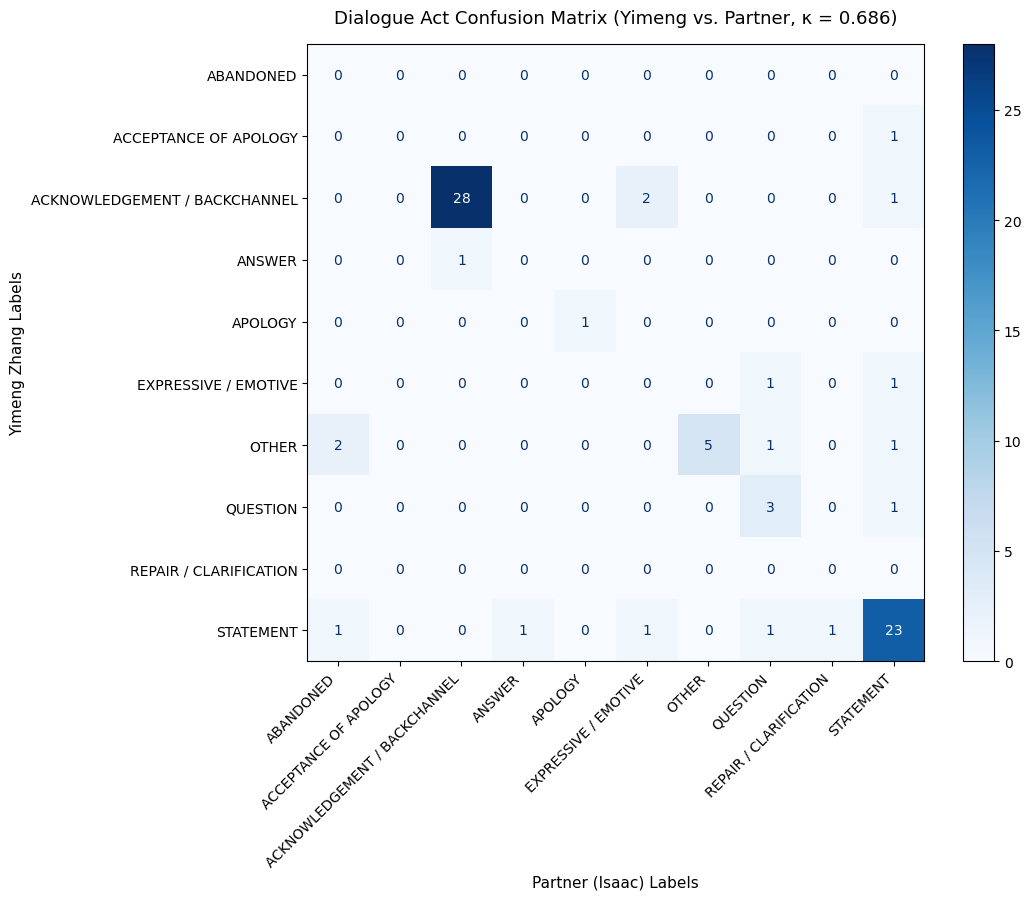

In [25]:
# Cohen's Kappa
import xml.etree.ElementTree as ET
import matplotlib.pyplot as plt
import pandas as pd
from sklearn.metrics import ConfusionMatrixDisplay, cohen_kappa_score, confusion_matrix


def load_eaf_data(eaf_path, target_tiers):
  tree = ET.parse(eaf_path)
  root = tree.getroot()

  utterances = {}
  for tier in root.findall("TIER"):
    speaker = tier.attrib.get("TIER_ID")
    if speaker in ["Aysha", "Yimeng"]:
      for ann in tier.findall("ANNOTATION/ALIGNABLE_ANNOTATION"):
        ann_id = ann.attrib["ANNOTATION_ID"]
        val_node = ann.find("ANNOTATION_VALUE")
        text = (
            val_node.text.strip()
            if (val_node is not None and val_node.text)
            else ""
        )
        utterances[ann_id] = (speaker, text)

  labels = {}
  for tier in root.findall("TIER"):
    if tier.attrib.get("TIER_ID") in target_tiers:
      for ann in tier.findall("ANNOTATION/REF_ANNOTATION"):
        ref_id = ann.attrib["ANNOTATION_REF"]
        val_node = ann.find("ANNOTATION_VALUE")
        val = (
            val_node.text.strip().upper()
            if (val_node is not None and val_node.text)
            else ""
        )
        labels[ref_id] = val

  return utterances, labels


def normalize_tag(tag):
  """To normalize different tags given by two annotators"""
  mapping = {
      "ACKNOWLEDGEMENT": "ACKNOWLEDGEMENT / BACKCHANNEL",
      "ACKNOWLEDGEMENT/BACKCHANNEL": "ACKNOWLEDGEMENT / BACKCHANNEL",
      "EXPRESSIVE": "EXPRESSIVE / EMOTIVE",
      "EXPRESSIVE/EMOTIVE": "EXPRESSIVE / EMOTIVE",
      "REPAIR/CLARIFICATION": "REPAIR / CLARIFICATION",
  }
  return mapping.get(tag, tag)

file_yimeng = "Transcript_DialogueActs Yimeng Zhang.eaf"
file_partner = "ZhangA2_v1_IR.eaf"

utts, labels_yimeng_raw = load_eaf_data(
    file_yimeng, ["DialogueAct_Aysha", "DialogueAct_Yimeng"]
)
_, labels_partner_raw = load_eaf_data(
    file_partner, ["DialogueActs_Aysha", "DialogueActs_Yimeng"]
)

sorted_ids = sorted(utts.keys(), key=lambda x: int(x[1:]))
y_yimeng = [normalize_tag(labels_yimeng_raw[i]) for i in sorted_ids]
y_partner = [normalize_tag(labels_partner_raw[i]) for i in sorted_ids]

# Calculate IAA using sklearn.metrics.cohen_kappa_score
kappa_score = cohen_kappa_score(y_yimeng, y_partner)
agreement_rate = sum(1 for a, b in zip(y_yimeng, y_partner) if a == b) / len(sorted_ids)

print(f"Total Utterances: {len(sorted_ids)}")
print(f"Raw Agreement Rate: {agreement_rate:.2%}")
print(f"Cohen's Kappa (κ): {kappa_score:.4f}\n")

# Confusion matrix
unique_labels = sorted(list(set(y_yimeng + y_partner)))
cm = confusion_matrix(y_yimeng, y_partner, labels=unique_labels)

fig, ax = plt.subplots(figsize=(11, 9))
disp = ConfusionMatrixDisplay(
    confusion_matrix=cm, display_labels=unique_labels
)
disp.plot(cmap="Blues", ax=ax, xticks_rotation=45, values_format="d")

plt.title(
    f"Dialogue Act Confusion Matrix (Yimeng vs. Partner, κ ="
    f" {kappa_score:.3f})",
    fontsize=13,
    pad=15,
)
plt.xlabel("Partner (Isaac) Labels", fontsize=11)
plt.ylabel("Yimeng Zhang Labels", fontsize=11)
plt.xticks(ha="right")
plt.tight_layout()
plt.savefig("part1_confusion_matrix.png", dpi=300)
plt.show()

In [26]:
# Get all mismatches for error analysis
mismatches = []
for i, ly, lp in zip(sorted_ids, y_yimeng, y_partner):
  if ly != lp:
    spk, txt = utts[i]
    mismatches.append({
        "ID": i,
        "Speaker": spk,
        "Utterance": txt,
        "Yimeng_Label": ly,
        "Isaac_Label": lp,
    })

df_mismatches = pd.DataFrame(mismatches)
print(f"Total Mismatches: {len(df_mismatches)}")
display(df_mismatches)

Total Mismatches: 17


,ID,Speaker,Utterance,Yimeng_Label,Isaac_Label
0,a3,Aysha,[The sauces.],STATEMENT,EXPRESSIVE / EMOTIVE
1,a9,Yimeng,[Cause.],OTHER,ABANDONED
2,a12,Aysha,"[Or maybe I did,] but I, cause the ones where ...",STATEMENT,REPAIR / CLARIFICATION
3,a17,Yimeng,"[Did,]",OTHER,QUESTION
4,a22,Yimeng,[It's not gonna be a.],OTHER,STATEMENT
5,a25,Yimeng,"[Sweet, chili.]",STATEMENT,ANSWER
6,a26,Yimeng,Yeah yeah yeah=,ANSWER,ACKNOWLEDGEMENT / BACKCHANNEL
7,a30,Aysha,[~A rat?~],EXPRESSIVE / EMOTIVE,QUESTION
8,a33,Aysha,"[=No exactly, that's my point,] or like, [yeah,]",ACKNOWLEDGEMENT / BACKCHANNEL,STATEMENT
9,a46,Aysha,"[Um,] but it was split in two, right? We had l...",QUESTION,STATEMENT
